## Construindo uma CNN para classificar imagens no Dataset CIFAR-10

Trabalharemos com o Dataset CIFAR-10. Este é um conjunto de dados bem conhecido para classificação de imagens, que consiste em 60.000 imagens coloridas de 32x32 pixels divididas em 10 classes, com 6.000 imagens por classe. Há 50.000 imagens de treinamento e 10.000 imagens de teste.

As 10 classes são:

<ol start="0">
<li> avião
<li> automóvel
<li> pássaro
<li> gato
<li> veado
<li> cachorro
<li> sapo
<li> cavalo
<li> navio
<li> caminhão
</ol>

Para detalhes sobre o CIFAR-10, consulte:
https://www.cs.toronto.edu/~kriz/cifar.html

Para uma compilação de resultados de desempenho publicados no CIFAR-10, consulte:
http://rodrigob.github.io/are_we_there_yet/build/classification_datasets_results.html

---

### Construindo Redes Neurais Convolucionais

Neste exercício, construiremos e treinaremos nossas primeiras redes neurais convolucionais. Na primeira parte, percorreremos as diferentes camadas e como elas são configuradas. Na segunda parte, você construirá seu próprio modelo, o treinará e comparará o desempenho.

In [1]:
# Preliminares

from __future__ import absolute_import, division, print_function  # Compatibilidade Python 2/3

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Importar objetos do Keras para Deep Learning

import tensorflow.keras as keras
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import RMSprop, Adam
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1789582235.244136  118925 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Os dados, embaralhados e divididos entre conjuntos de treino e teste:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print('formato x_train:', x_train.shape)
print(x_train.shape[0], 'amostras de treino')
print(x_test.shape[0], 'amostras de teste')

formato x_train: (50000, 32, 32, 3)
50000 amostras de treino
10000 amostras de teste


In [4]:
# Cada imagem é um array numpy 32 x 32 x 3
x_train[444].shape

(32, 32, 3)

[9]


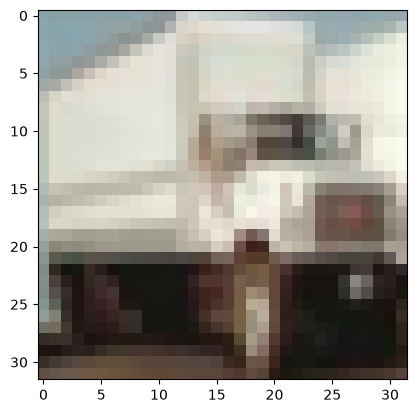

In [5]:
# Vamos observar uma das imagens

print(y_train[444])
plt.imshow(x_train[444])

In [6]:
num_classes = 10

y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

In [7]:
# agora, em vez de classes descritas por um inteiro entre 0-9, temos um vetor com um 1 na 9ª posição (indexação do Python)
y_train[444]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

In [8]:
# Como antes, vamos fazer tudo float e escalar
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

## Camadas do Keras para CNNs
- Anteriormente, construímos Redes Neurais usando principalmente as camadas Dense, Activation e Dropout.

- Aqui descreveremos como usar algumas das camadas específicas para CNN fornecidas pelo Keras

### Conv2D

```python
keras.layers.convolutional.Conv2D(filters, kernel_size, strides=(1, 1), padding='valid', data_format=None, dilation_rate=(1, 1), activation=None, use_bias=True, kernel_initializer='glorot_uniform', bias_initializer='zeros', kernel_regularizer=None, bias_regularizer=None, activity_regularizer=None, kernel_constraint=None, bias_constraint=None, **kwargs)
```

Alguns parâmetros explicados:
- `filters`: o número de filtros usados por localização. Em outras palavras, a profundidade da saída.
- `kernel_size`: uma tupla (x,y) fornecendo a altura e largura do kernel a ser usado
- `strides`: uma tupla (x,y) fornecendo o passo em cada dimensão. O padrão é `(1,1)`
- `input_shape`: necessário apenas para a primeira camada

Note que o tamanho da saída será determinado pelo kernel_size e strides

### MaxPooling2D
`keras.layers.pooling.MaxPooling2D(pool_size=(2, 2), strides=None, padding='valid', data_format=None)`

- `pool_size`: o tamanho (x,y) da grade a ser agrupada.
- `strides`: Assumido como sendo o `pool_size` a menos que especificado de outra forma

### Flatten
Transforma sua entrada em um vetor unidimensional (por instância). Geralmente usado ao fazer a transição entre camadas convolucionais e camadas totalmente conectadas.

---

## Primeira CNN
Abaixo construiremos nossa primeira CNN. Para fins de demonstração (para que treine rapidamente), ela não é muito profunda e tem relativamente poucos parâmetros. Usamos strides de 2 nas duas primeiras camadas convolucionais, o que reduz rapidamente as dimensões da saída. Após uma camada MaxPooling, fazemos o flatten e então temos uma única camada totalmente conectada antes de nossa camada de classificação final.

In [9]:
# Vamos construir uma CNN usando as capacidades Sequential do Keras

model_1 = Sequential()


# Convolução 5x5 com stride 2x2 e 32 filtros
model_1.add(Conv2D(filters=32, kernel_size=(5, 5), strides=(2,2), padding='same',
                 input_shape=x_train.shape[1:]))
model_1.add(Activation('relu'))

# Outra convolução 5x5 com stride 2x2 e 32 filtros
model_1.add(Conv2D(filters=32, kernel_size=(5, 5), strides=(2,2)))
model_1.add(Activation('relu'))

# Max pooling 2x2 reduz para 3 x 3 x 32
model_1.add(MaxPooling2D(pool_size=(2, 2)))
model_1.add(Dropout(0.25))

# Flatten transforma 3x3x32 em 288x1
model_1.add(Flatten())
model_1.add(Dense(512))
model_1.add(Activation('relu'))
model_1.add(Dropout(0.5))
model_1.add(Dense(num_classes))
model_1.add(Activation('softmax'))

model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 32)       │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       147,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181,162 (707.66 KB)

 Trainable params: 181,162 (707.66 KB)

 Non-trainable params: 0 (0.00 B)

Ainda temos 181K parâmetros, mesmo sendo um modelo "pequeno".

In [10]:
batch_size = 32

# inicializar otimizador RMSprop
opt = RMSprop(learning_rate=0.0005, decay=1e-6)

# Vamos treinar o modelo usando RMSprop
model_1.compile(loss='categorical_crossentropy',
              optimizer=opt,
              metrics=['accuracy'])

model_1.fit(x_train, y_train,
              batch_size=batch_size,
              epochs=15,
              validation_data=(x_test, y_test),
              shuffle=True)

Epoch 1/15


W0000 00:00:1789582252.827419  118925 cpu_allocator_impl.cc:82] Allocation of 614400000 exceeds 10% of free system memory.


1561/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3602 - loss: 1.7441

W0000 00:00:1789582271.062245  118925 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.3601 - loss: 1.7442 - val_accuracy: 0.4342 - val_loss: 1.5989
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.4684 - loss: 1.4697 - val_accuracy: 0.5050 - val_loss: 1.4149
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.5184 - loss: 1.3445 - val_accuracy: 0.5608 - val_loss: 1.2183
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.5492 - loss: 1.2666 - val_accuracy: 0.5738 - val_loss: 1.1954
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.5681 - loss: 1.2222 - val_accuracy: 0.5973 - val_loss: 1.1415
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.5824 - loss: 1.1813 - val_accuracy: 0.5955 - val_loss: 1.1600
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.5944 - loss: 1.1601 - val_accuracy: 0.6065 - val_loss: 1.1057
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.5994 - loss: 1.13

### Exercício
Nosso modelo anterior tinha a estrutura:

Conv -> Conv -> MaxPool -> (Flatten) -> Dense -> Classificação Final

(com funções de ativação e dropouts apropriados)

1. Construa um modelo mais complicado com o seguinte padrão:
- Conv -> Conv -> MaxPool -> Conv -> Conv -> MaxPool -> (Flatten) -> Dense -> Classificação Final

- Use strides de 1 para todas as camadas convolucionais.

2. Quantos parâmetros seu modelo tem? Como isso se compara ao modelo anterior?

3. Treine-o por 5 épocas. O que você observa sobre o tempo de treinamento, perda e números de acurácia (tanto nos conjuntos de treinamento quanto de validação)?

5. Experimente diferentes estruturas e tempos de execução, e veja quão preciso seu modelo pode ser.

In [11]:
# Forneça sua solução aqui
# Crie model_2 conforme mencionado no exercício

model2 = Sequential()

#usando padding same pra adicionar bordas e evitar perder pixels, deixando a responsabilidade pro maxpooling
#pesquisei sobre como escolher kernel_size, encontrei que usar (3,3) e empilhar ele é mais eficiente que (5, 5) e maiores
 
model2.add(Conv2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=x_train.shape[1:]))
model2.add(Activation("relu"))
model2.add(Conv2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding="same"))
model2.add(Activation("relu"))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Conv2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding='same'))
model2.add(Activation("relu"))
model2.add(Conv2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding="same"))
model2.add(Activation("relu"))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Flatten())
model2.add(Dense(256, activation="relu"))
model2.add(Dropout(0.5))
model2.add(Dense(10, activation="softmax"))

model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 555,754 (2.12 MB)

 Trainable params: 555,754 (2.12 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
"""O novo modelo tem 555k parametros, mais que o dobro dos 180k do outro modelo"""

'O novo modelo tem 555k parametros, mais que o dobro dos 180k do outro modelo'

In [13]:
model2.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.001),
              metrics=['accuracy'])

#Devido ser apenas 5 épocas, vou precisar fazer algumas sub épocas para facilitar o plot
pontos_no_grafico = 20 
passos_totais = (len(x_train) // batch_size) * 5
passos_sub_epoca = passos_totais // pontos_no_grafico

history = model2.fit(x_train, y_train,
              batch_size=64,
              epochs=pontos_no_grafico,
              steps_per_epoch=passos_sub_epoca,
              validation_data=(x_test, y_test),
              shuffle=True)

Epoch 1/20


W0000 00:00:1789582540.771274  118925 cpu_allocator_impl.cc:82] Allocation of 614400000 exceeds 10% of free system memory.


390/390 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.3589 - loss: 1.7496

W0000 00:00:1789582589.963751  118925 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


390/390 ━━━━━━━━━━━━━━━━━━━━ 51s 123ms/step - accuracy: 0.3589 - loss: 1.7496 - val_accuracy: 0.4966 - val_loss: 1.3959
Epoch 2/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 122ms/step - accuracy: 0.5058 - loss: 1.3727 - val_accuracy: 0.5822 - val_loss: 1.1866
Epoch 3/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6125 - loss: 1.0836 - val_accuracy: 0.5913 - val_loss: 1.1834
Epoch 4/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 51s 132ms/step - accuracy: 0.5729 - loss: 1.1943 - val_accuracy: 0.6286 - val_loss: 1.0521
Epoch 5/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 47s 120ms/step - accuracy: 0.6112 - loss: 1.0933 - val_accuracy: 0.6563 - val_loss: 0.9714
Epoch 6/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6875 - loss: 0.8714 - val_accuracy: 0.6584 - val_loss: 0.9696
Epoch 7/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 53s 136ms/step - accuracy: 0.6545 - loss: 0.9820 - val_accuracy: 0.6801 - val_loss: 0.9067
Epoch 8/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 52s 132ms/step - accuracy: 0.6653 - loss: 0.9588 - val_accur

 12/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7370 - loss: 0.7305

W0000 00:00:1789583266.710827  118925 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7449 - loss: 0.7458
Perda no Teste: 0.7458462715148926, Acurácia no Teste: 0.7448999881744385


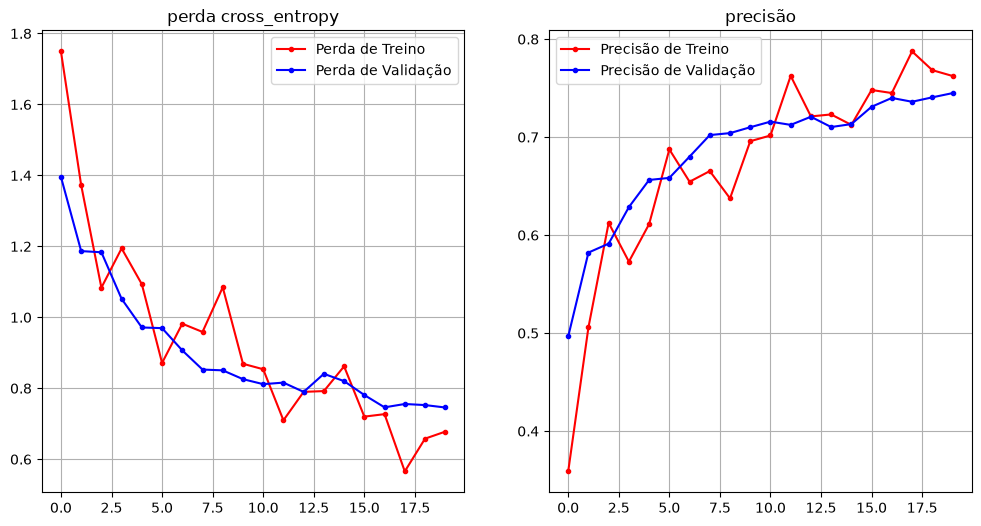

In [14]:
def plot_loss_accuracy(history):
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
    ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")
    ax.legend()
    ax.set_title('perda cross_entropy')
    ax.grid(True)


    ax = fig.add_subplot(1, 2, 2)
    ax.plot(history.history["accuracy"],'r', marker='.', label="Precisão de Treino")
    ax.plot(history.history["val_accuracy"],'b', marker='.', label="Precisão de Validação")
    ax.legend()
    ax.set_title('precisão')
    ax.grid(True)

score = model2.evaluate(x_test, y_test, verbose='auto')
print(f'Perda no Teste: {score[0]}, Acurácia no Teste: {score[1]}')

plot_loss_accuracy(history)

In [15]:
"""O modelo aprendeu pouco e não desempenha bem, não tem uma acurácia nem loss satisfatória, além de ainda
não ter conseguido estabilizar os parâmetros. Vamos tentar um outro modelo com mais épocas e filtros graduais 
nas convulações ( pesquisei sobre e achei isso como o recomendado ). Vou por um earlystopping devido ao 
número de épocas. O modelo antigo demorou 10 minutos de treino, vamos ver esse. """



'O modelo aprendeu pouco e não desempenha bem, não tem uma acurácia nem loss satisfatória, além de ainda\nnão ter conseguido estabilizar os parâmetros. Vamos tentar um outro modelo com mais épocas e filtros graduais \nnas convulações ( pesquisei sobre e achei isso como o recomendado ). Vou por um earlystopping devido ao \nnúmero de épocas. O modelo antigo demorou 10 minutos de treino, vamos ver esse. '

In [16]:

model3 = Sequential()

"""RODEI APENAS AUMENTADO OS FILTROS E O NÙMERO DE PARÂMETROS FOI PRA 4 MILHOES NAS CAMADAS FINAIS,
VOU ADICIONAR MAIS POOLINGS"""
 
model3.add(Conv2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=x_train.shape[1:]))
model3.add(Activation("relu"))
model3.add(Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding="same"))
model3.add(Activation("relu"))
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Conv2D(filters=128, kernel_size=(3, 3), strides=(1, 1), padding='same'))
model3.add(Activation("relu"))
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Conv2D(filters=256, kernel_size=(3, 3), strides=(1, 1), padding="same"))
model3.add(Activation("relu"))
model3.add(MaxPooling2D(pool_size=(2, 2)))
model3.add(Flatten())
model3.add(Dense(256, activation="relu"))
model3.add(Dropout(0.5))
model3.add(Dense(10, activation="softmax"))

model3.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.001),
              metrics=['accuracy'])

model3.summary()



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,439,818 (5.49 MB)

 Trainable params: 1,439,818 (5.49 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
pontos_no_grafico = 40
passos_totais = (len(x_train) // batch_size) * 20
passos_sub_epoca = passos_totais // pontos_no_grafico

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True)

history2 = model3.fit(x_train, y_train,
              batch_size=64,
              epochs=pontos_no_grafico,
              steps_per_epoch=passos_sub_epoca,
              validation_data=(x_test, y_test),
              shuffle=True,
              callbacks=[early_stop])

Epoch 1/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 203s 257ms/step - accuracy: 0.4246 - loss: 1.5716 - val_accuracy: 0.6053 - val_loss: 1.1440
Epoch 2/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.6250 - loss: 1.0941 - val_accuracy: 0.6046 - val_loss: 1.1423
Epoch 3/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 212s 272ms/step - accuracy: 0.6272 - loss: 1.0602 - val_accuracy: 0.6923 - val_loss: 0.8746
Epoch 4/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.5625 - loss: 1.3302 - val_accuracy: 0.7001 - val_loss: 0.8601
Epoch 5/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 214s 274ms/step - accuracy: 0.7032 - loss: 0.8591 - val_accuracy: 0.7254 - val_loss: 0.7955
Epoch 6/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6875 - loss: 0.9011 - val_accuracy: 0.7243 - val_loss: 0.7924
Epoch 7/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 205s 263ms/step - accuracy: 0.7487 - loss: 0.7269 - val_accuracy: 0.7563 - val_loss: 0.7183
Epoch 8/40
781/781 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7500 - loss: 0.7

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.7891 - loss: 0.6440
Perda no Teste: 0.644003689289093, Acurácia no Teste: 0.7890999913215637


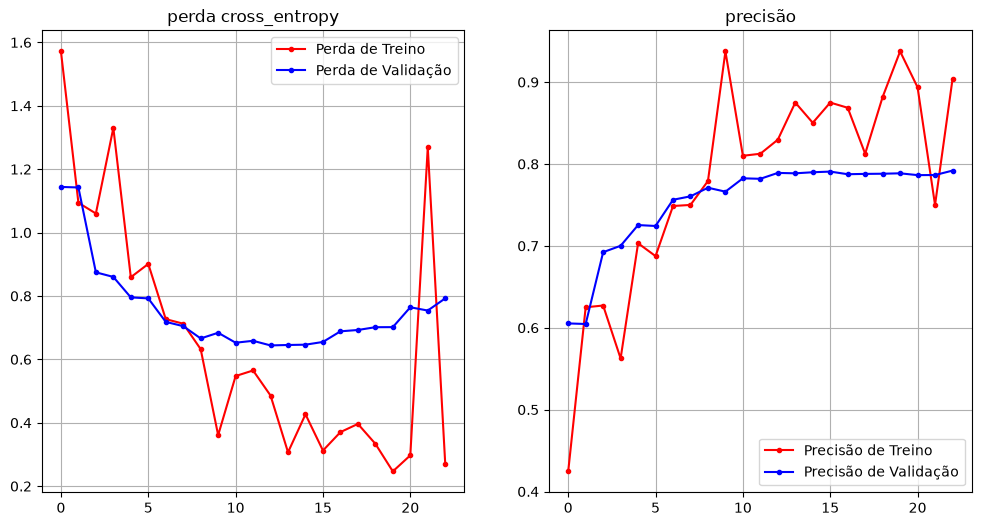

In [ ]:
score2 = model3.evaluate(x_test, y_test, verbose='auto')
print(f'Perda no Teste: {score2[0]}, Acurácia no Teste: {score2[1]}')

plot_loss_accuracy(history2)

In [ ]:
"""É visível no gráfico quando o loss de validação começa a estabilizar a subir, começando a indicar overfitting, e 
acurácia de treino e de validação começam a se distanciar demais e em picos, indicando overfitting. A acurácia e o loss
foram melhores, mas ainda não é um desempenho totalmente satisfatório. Eu diminuiria o número de épocas/aumentaria
o batch size e diminuiria o learning_rate, esse modelo me levou quase 1 hora rodando. (eu poderia começar retirando as subépocas
e não priorizar tanto o gráfico, visando perfomance)
Um ponto é que esqueci de por o otimizador Adam no modelo 3. 
Eu também poderia testar usar regularizador l2. Aqui estão minhas sugestões.
Tentei rodar no collab mas estava aparentando problemas, tive que rodar na minha
máquina, que não tem gpu e é bem fraca, gostaria de testar esse modelo4, mas o tempo e as condições não favorecem, espero que entenda"""


"""OBS: Ainda não vimos em aula muito sobre, mas encontrei sobre data augmentation para esse dataset de imagens e 
usar batchnormalization"""